# 01 — Exploratory Data Analysis: WitFoo Precinct6 `signals`

**Scope.** Read-only EDA of `signals/signals.parquet`, loaded with the project loader
`evidentia.ml.data.load_signals()` and the project label column `label_binary`
(benign / suspicious / malicious, not redefined here).

**Train-only rule.** Every statistic that informs a modelling decision is computed on the
**training portion only**: rows with `timestamp < CUTOFFS[org_id]` (the same temporal cut-offs the
pipeline uses, from `evidentia.ml.config`). Test rows appear only in the split-visualisation chart (§7).

Every number in the interpretation notes is printed by code (rendered with `display(Markdown(...))`).

In [1]:
import sys, time, json, re, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import duckdb
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from sklearn.metrics import normalized_mutual_info_score, f1_score

T0 = time.time()
ROOT = Path.cwd().resolve()
if not (ROOT / "evidentia").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from evidentia.ml.config import (CUTOFFS, LABELS, BANNED_POST_LABEL, SOURCE_FIELDS, NEVER_FEATURES,
                                 SIGNALS_PARQUET, STAGE2_ORGS, SEED)
from evidentia.ml.data import load_signals

np.random.seed(SEED)
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

COLOR = {"benign": "#2a78d6", "suspicious": "#eb6834", "malicious": "#1baf7a"}
ORG_COL = {"ORG-0004": "#2a78d6", "ORG-0005": "#eb6834", "ORG-0003": "#1baf7a", "ORG-0001": "#eda100"}
INK, INK2, MUTED, GRID, AXIS, SURF = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 11,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 11, "legend.frameon": False})

def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / name, dpi=200)
    plt.show()
    print("saved", FIG / name)

def pct(x): return f"{100*x:.2f}%"
FINDINGS = {}   # collected for reports/eda_summary.md

## 0. Load data and define the training portion

In [2]:
df = load_signals()
df["is_test"] = df["timestamp"] >= df["org_id"].map(CUTOFFS).astype(float)
df["ts"] = pd.to_datetime(df["timestamp"], unit="s", utc=True)
train = df.loc[~df["is_test"]].copy()

# Keep only what §7 needs from the test portion, then free memory.
coverage_all = df[["org_id", "ts", "is_test", "label_binary"]].copy()
n_all, n_train = len(df), len(train)

# Coverage span per organisation (all rows): used in the limitations instead of a hard-coded value.
span = df.groupby("org_id")["timestamp"].agg(["min", "max"])
span_days = ((span["max"] - span["min"]) / 86400).round(2)
FINDINGS["coverage_span_days"] = span_days.to_dict()

# Same rule as evidentia.ml.data.build_dataset: malicious TRAIN rows whose incident also appears
# in the test portion are dropped from training by the pipeline. Counted here (not dropped in EDA).
def _incs(s):
    return set(json.loads(s)) if isinstance(s, str) and s else set()
mal = df["label_binary"] == "malicious"
test_inc = set().union(*df.loc[mal & df["is_test"], "incident_ids"].map(_incs))
crossing = df.loc[mal & ~df["is_test"], "incident_ids"].map(lambda s: bool(_incs(s) & test_inc))
FINDINGS["train_rows_dropped_crossing_incidents"] = int(crossing.sum())
FINDINGS["crossing_rows_by_org"] = df.loc[crossing[crossing].index, "org_id"].value_counts().to_dict()
del df
print("coverage span (days):", FINDINGS["coverage_span_days"])
print("malicious train rows in incidents that cross a cut-off:", FINDINGS["train_rows_dropped_crossing_incidents"],
      FINDINGS["crossing_rows_by_org"])

FINDINGS["rows_all"], FINDINGS["rows_train"] = n_all, n_train
print(f"all rows: {n_all:,} | train rows: {n_train:,} ({n_train/n_all:.1%})")
print("cut-offs (UTC):", {k: pd.to_datetime(v, unit='s', utc=True).strftime('%Y-%m-%d %H:%M') for k, v in CUTOFFS.items()})
train.groupby(["org_id", "label_binary"]).size().unstack(fill_value=0)[LABELS]

coverage span (days): {'ORG-0001': 0.78, 'ORG-0003': 0.78, 'ORG-0004': 5.78, 'ORG-0005': 0.78}
malicious train rows in incidents that cross a cut-off: 137 {'ORG-0005': 136, 'ORG-0003': 1}
all rows: 2,011,674 | train rows: 1,045,818 (52.0%)
cut-offs (UTC): {'ORG-0004': '2024-07-29 20:00', 'ORG-0005': '2024-07-27 00:00', 'ORG-0003': '2024-07-27 00:00', 'ORG-0001': '2024-07-27 00:00'}


label_binary,benign,suspicious,malicious
org_id,,,
ORG-0001,2690,7,0
ORG-0003,138934,59,3
ORG-0004,588268,4838,1063
ORG-0005,259642,47660,2654


## 1. Class distribution (train)

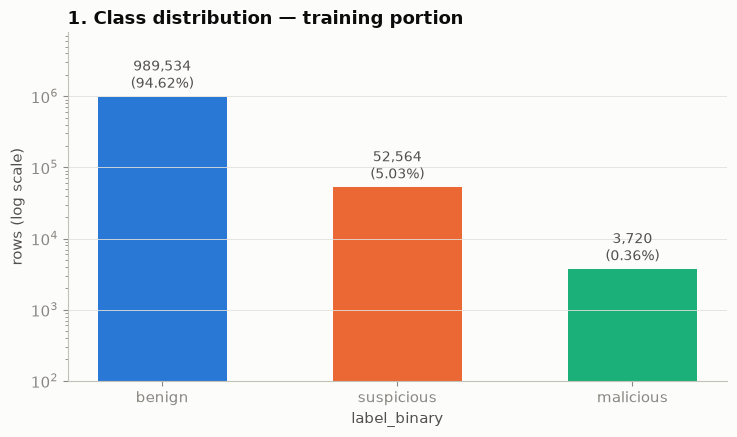

saved C:\Users\iComputers\Documents\Sem 5\PAI Project\EVIDENTIA AI\reports\figures\eda01_class_distribution.png


**What this means for modelling:** malicious is 0.36% of training rows (266 benign rows per malicious row). Accuracy is meaningless here (predicting all-benign scores 94.62%); use class weights and report macro-F1 / PR-AUC.

In [3]:
cnt = train["label_binary"].value_counts().reindex(LABELS)
share = cnt / cnt.sum()
fig, ax = plt.subplots(figsize=(7.5, 4.5))
bars = ax.bar(LABELS, cnt.values, color=[COLOR[l] for l in LABELS], width=0.55)
ax.set_yscale("log"); ax.set_ylim(1e2, cnt.max() * 8)
for b, l in zip(bars, LABELS):
    ax.annotate(f"{cnt[l]:,}\n({pct(share[l])})", (b.get_x() + b.get_width()/2, cnt[l]), ha="center",
                va="bottom", fontsize=10, color=INK2, xytext=(0, 3), textcoords="offset points")
ax.set_xlabel("label_binary"); ax.set_ylabel("rows (log scale)")
ax.set_title("1. Class distribution — training portion")
ax.grid(axis="x", visible=False)
save(fig, "eda01_class_distribution.png")
ratio = cnt["benign"] / cnt["malicious"]
FINDINGS["class_counts"] = cnt.to_dict(); FINDINGS["class_share"] = share.round(4).to_dict()
display(Markdown(f"**What this means for modelling:** malicious is {pct(share['malicious'])} of training rows "
                 f"({ratio:,.0f} benign rows per malicious row). Accuracy is meaningless here "
                 f"(predicting all-benign scores {pct(share['benign'])}); use class weights and report macro-F1 / PR-AUC."))

## 2. Organisation-wise counts and class mix (train)

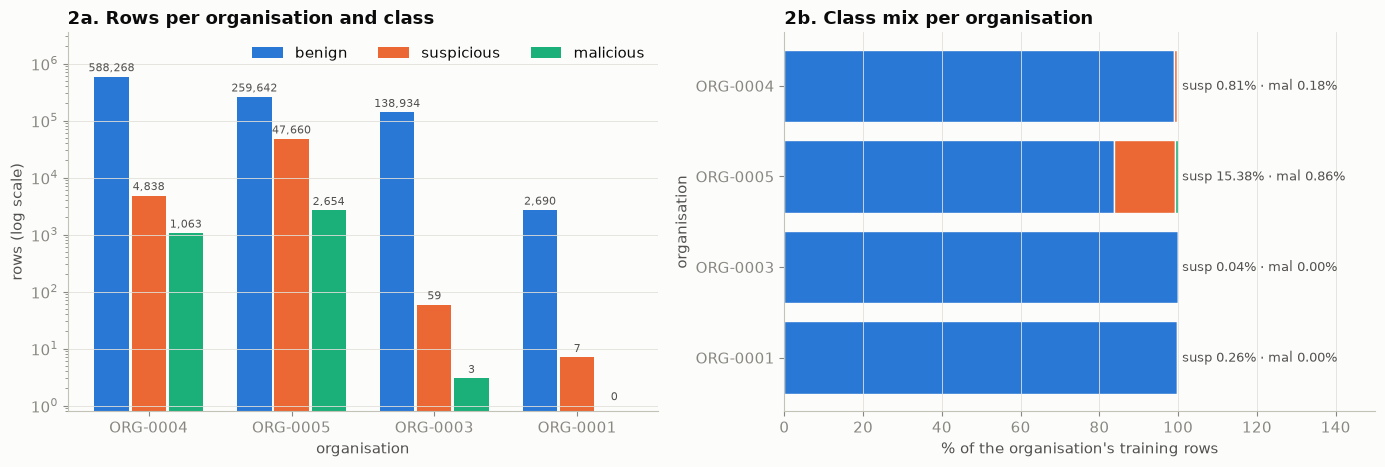

saved C:\Users\iComputers\Documents\Sem 5\PAI Project\EVIDENTIA AI\reports\figures\eda02_org_class_mix.png


**What this means for modelling:** only ORG-0004, ORG-0005 have ≥500 malicious training rows (ORG-0004: 1,063, ORG-0005: 2,654, ORG-0003: 3, ORG-0001: 0). The suspicious rate differs strongly by org (ORG-0004: 0.81%, ORG-0005: 15.38%, ORG-0003: 0.04%, ORG-0001: 0.26%), so `org_id` must never be a feature and results must be reported per org.

In [4]:
org_tab = train.groupby(["org_id", "label_binary"]).size().unstack(fill_value=0).reindex(columns=LABELS)
org_tab = org_tab.loc[org_tab.sum(axis=1).sort_values(ascending=False).index]
mix = org_tab.div(org_tab.sum(axis=1), axis=0)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
x = np.arange(len(org_tab)); w = 0.26
for i, l in enumerate(LABELS):
    v = org_tab[l].values
    b = axes[0].bar(x + (i-1)*w, np.maximum(v, 0.8), w-0.02, color=COLOR[l], label=l)
    for bb, vv in zip(b, v):
        axes[0].annotate(f"{vv:,}", (bb.get_x()+bb.get_width()/2, max(vv, 1)), ha="center", va="bottom",
                         fontsize=8, color=INK2, xytext=(0, 2), textcoords="offset points")
axes[0].set_yscale("log"); axes[0].set_ylim(0.8, org_tab.values.max()*6)
axes[0].set_xticks(x, org_tab.index); axes[0].set_xlabel("organisation"); axes[0].set_ylabel("rows (log scale)")
axes[0].set_title("2a. Rows per organisation and class"); axes[0].legend(ncols=3, loc="upper right")
axes[0].grid(axis="x", visible=False)
left = np.zeros(len(mix))
for l in LABELS:
    axes[1].barh(mix.index, mix[l]*100, left=left, color=COLOR[l], label=l, edgecolor=SURF)
    left += mix[l].values*100
for i, o in enumerate(mix.index):
    axes[1].annotate(f"susp {pct(mix.loc[o,'suspicious'])} · mal {pct(mix.loc[o,'malicious'])}",
                     (101, i), va="center", fontsize=9, color=INK2)
axes[1].invert_yaxis(); axes[1].set_xlim(0, 150)
axes[1].set_xlabel("% of the organisation's training rows"); axes[1].set_ylabel("organisation")
axes[1].set_title("2b. Class mix per organisation"); axes[1].grid(axis="y", visible=False)
save(fig, "eda02_org_class_mix.png")
usable = [o for o in org_tab.index if org_tab.loc[o, "malicious"] >= 500]
FINDINGS["org_table"] = org_tab.to_dict(orient="index"); FINDINGS["orgs_with_500plus_malicious"] = usable
display(Markdown(f"**What this means for modelling:** only {', '.join(usable)} have ≥500 malicious training rows "
                 f"({', '.join(f'{o}: {org_tab.loc[o, 'malicious']:,}' for o in org_tab.index)}). "
                 f"The suspicious rate differs strongly by org ({', '.join(f'{o}: {pct(mix.loc[o, 'suspicious'])}' for o in mix.index)}), so `org_id` must never be a feature and results must be reported per org."))

## 3. Hourly activity (UTC) and daily volume (train)

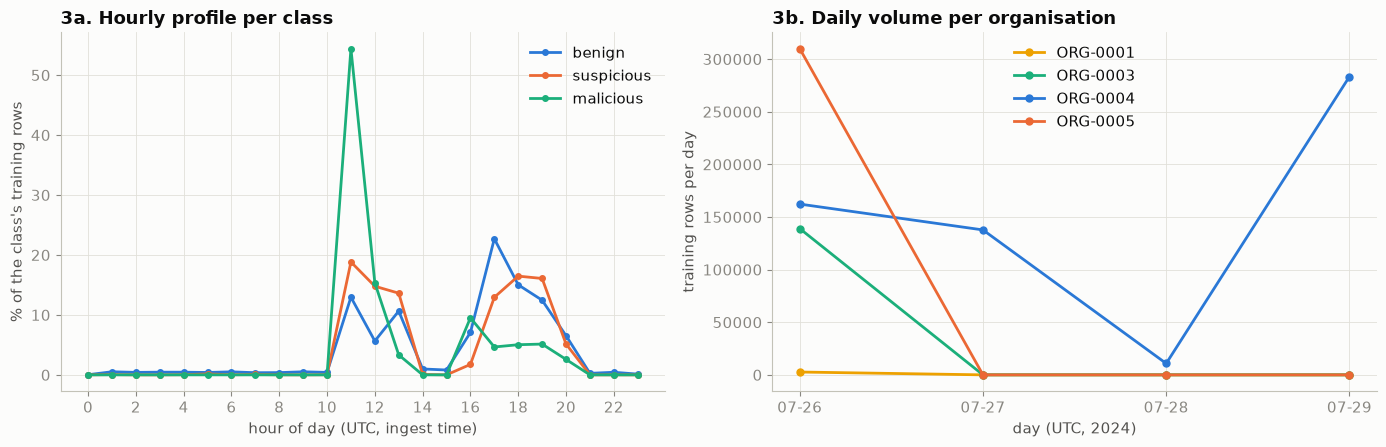

saved C:\Users\iComputers\Documents\Sem 5\PAI Project\EVIDENTIA AI\reports\figures\eda03_hourly_daily.png


**What this means for modelling:** 54.41% of malicious training rows fall in a single hour (11:00 UTC): malicious events arrive in bursts. Hour-of-day would act as a burst identifier, so it is **not** used as a feature; splits must be temporal, not random.

In [5]:
train["hour"] = train["ts"].dt.hour
train["day"] = train["ts"].dt.strftime("%m-%d")
hourly = train.groupby(["hour", "label_binary"]).size().unstack(fill_value=0).reindex(index=range(24), columns=LABELS, fill_value=0)
hshare = hourly / hourly.sum(axis=0)
daily = train.groupby(["day", "org_id"]).size().unstack(fill_value=0)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
for l in LABELS:
    axes[0].plot(hshare.index, hshare[l]*100, marker="o", ms=4, lw=2, color=COLOR[l], label=l)
axes[0].set_xticks(range(0, 24, 2)); axes[0].set_xlabel("hour of day (UTC, ingest time)")
axes[0].set_ylabel("% of the class's training rows"); axes[0].set_title("3a. Hourly profile per class"); axes[0].legend()
for o in daily.columns:
    axes[1].plot(daily.index, daily[o], marker="o", ms=5, lw=2, color=ORG_COL.get(o, MUTED), label=o)
axes[1].set_xlabel("day (UTC, 2024)"); axes[1].set_ylabel("training rows per day")
axes[1].set_title("3b. Daily volume per organisation"); axes[1].legend()
save(fig, "eda03_hourly_daily.png")
mal_peak = int(hshare["malicious"].idxmax()); mal_peak_share = hshare["malicious"].max()
FINDINGS["malicious_peak_hour_utc"] = mal_peak; FINDINGS["malicious_peak_hour_share"] = round(float(mal_peak_share), 4)
display(Markdown(f"**What this means for modelling:** {pct(mal_peak_share)} of malicious training rows fall in a single hour "
                 f"({mal_peak:02d}:00 UTC): malicious events arrive in bursts. Hour-of-day would act as a burst identifier, "
                 f"so it is **not** used as a feature; splits must be temporal, not random."))

## 4. Top 15 `message_type` and class proportion per type (train)

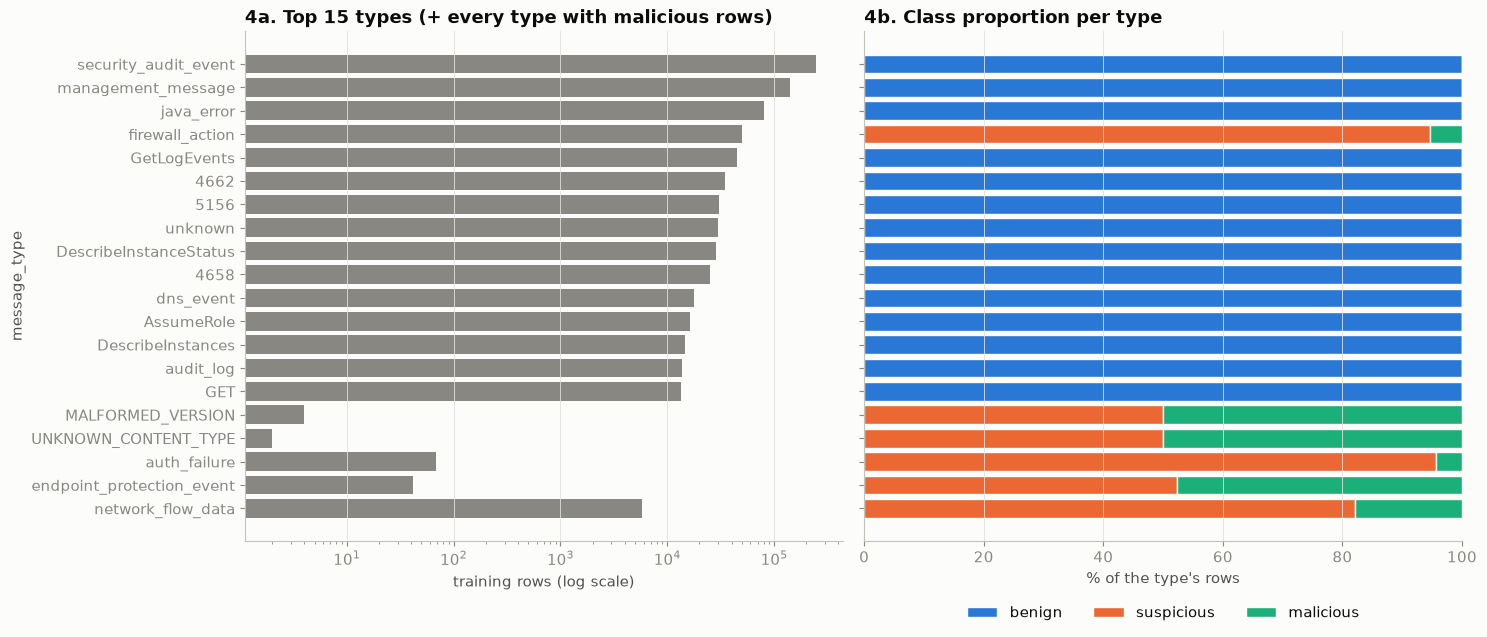

saved C:\Users\iComputers\Documents\Sem 5\PAI Project\EVIDENTIA AI\reports\figures\eda04_message_types.png


**What this means for modelling:** 470 message types in training, but 99.77% of suspicious+malicious rows come from just two (firewall_action, network_flow_data). Benign-vs-alert is largely a *log-type* question; the hard problem is suspicious-vs-malicious **within** those types, where `message_type` cannot help.

In [6]:
mt = train.groupby(["message_type", "label_binary"]).size().unstack(fill_value=0).reindex(columns=LABELS, fill_value=0)
top = mt.loc[mt.sum(axis=1).sort_values(ascending=False).index[:15]]
# also keep every type that contains malicious rows, so the minority classes are visible
mal_types = mt.index[mt["malicious"] > 0]
show = pd.concat([top, mt.loc[[t for t in mal_types if t not in top.index]]])
prop = show.div(show.sum(axis=1), axis=0)
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5), sharey=True)
axes[0].barh(show.index, show.sum(axis=1), color=MUTED)
axes[0].set_xscale("log"); axes[0].invert_yaxis()
axes[0].set_xlabel("training rows (log scale)"); axes[0].set_ylabel("message_type")
axes[0].set_title("4a. Top 15 types (+ every type with malicious rows)")
left = np.zeros(len(prop))
for l in LABELS:
    axes[1].barh(prop.index, prop[l]*100, left=left, color=COLOR[l], label=l, edgecolor=SURF)
    left += prop[l].values*100
axes[1].set_xlabel("% of the type's rows"); axes[1].set_title("4b. Class proportion per type")
axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncols=3)
for ax in axes: ax.grid(axis="y", visible=False)
save(fig, "eda04_message_types.png")
nonbenign_types = mt[(mt["suspicious"] + mt["malicious"]) > 0]
conc = (nonbenign_types[["suspicious", "malicious"]].sum(axis=1).sort_values(ascending=False))
top2_share = conc.iloc[:2].sum() / conc.sum()
FINDINGS["n_message_types_train"] = int(len(mt)); FINDINGS["top2_types_share_of_alerts"] = round(float(top2_share), 4)
FINDINGS["top2_alert_types"] = list(conc.index[:2])
display(Markdown(f"**What this means for modelling:** {len(mt)} message types in training, but {pct(top2_share)} of suspicious+malicious rows "
                 f"come from just two ({', '.join(conc.index[:2])}). Benign-vs-alert is largely a *log-type* question; "
                 f"the hard problem is suspicious-vs-malicious **within** those types, where `message_type` cannot help."))

## 5. Missing values per column (train)

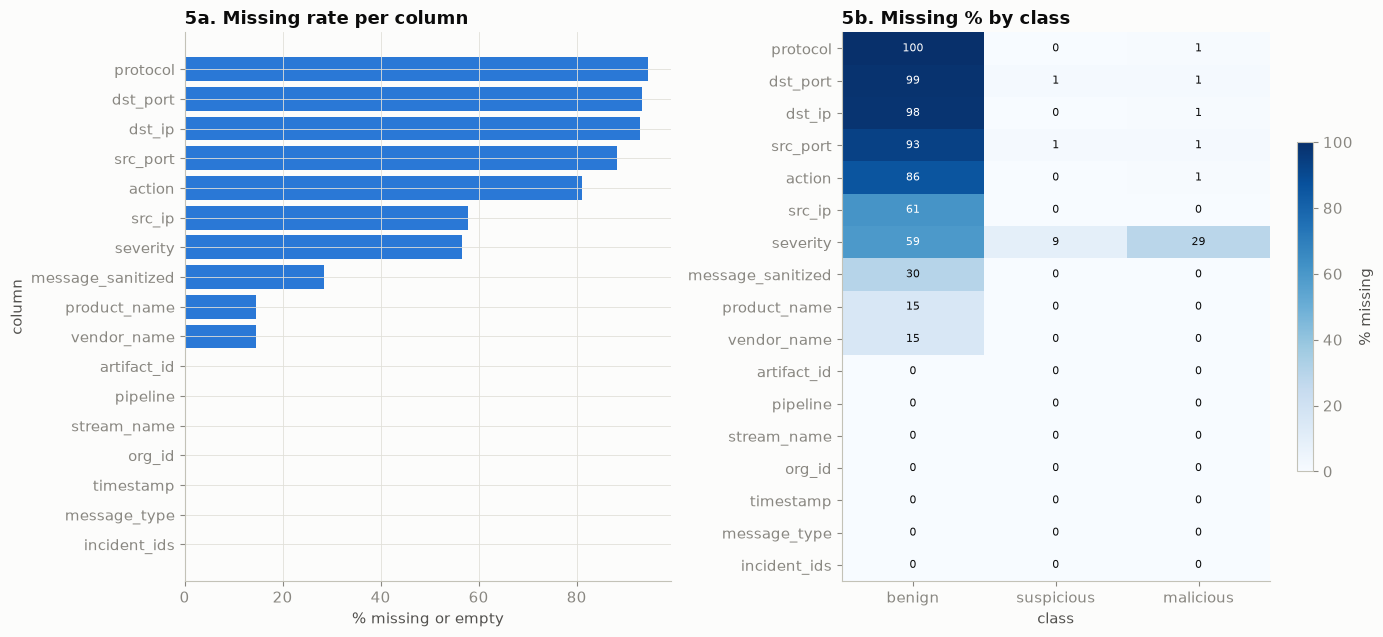

saved C:\Users\iComputers\Documents\Sem 5\PAI Project\EVIDENTIA AI\reports\figures\eda05_missing_values.png


**What this means for modelling:** missingness differs by class — e.g. `protocol` is missing in 0.20%–99.95% of rows depending on class. Missing values are imputed as an explicit `none` category (never dropped), and missingness is treated as a possible log-source proxy in the source ablation.

In [7]:
cols = [c for c in train.columns if c not in ("is_test", "ts", "hour", "day", "label_binary")]
def missing(s):
    return s.isna() | (s.astype(str).str.strip() == "")
miss_all = pd.Series({c: missing(train[c]).mean() for c in cols}).sort_values(ascending=False)
miss_cls = pd.DataFrame({l: {c: missing(train.loc[train.label_binary == l, c]).mean() for c in cols} for l in LABELS}).loc[miss_all.index]
fig, axes = plt.subplots(1, 2, figsize=(14, 6.5), gridspec_kw={"width_ratios": [1, 1.1]})
axes[0].barh(miss_all.index, miss_all.values*100, color="#2a78d6")
axes[0].invert_yaxis(); axes[0].set_xlabel("% missing or empty"); axes[0].set_ylabel("column")
axes[0].set_title("5a. Missing rate per column")
im = axes[1].imshow(miss_cls.values*100, cmap="Blues", vmin=0, vmax=100, aspect="auto")
axes[1].set_xticks(range(3), LABELS); axes[1].set_yticks(range(len(miss_cls)), miss_cls.index); axes[1].grid(False)
for i in range(len(miss_cls)):
    for j in range(3):
        v = miss_cls.values[i, j]*100
        axes[1].text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8, color="#ffffff" if v > 55 else INK)
axes[1].set_xlabel("class"); axes[1].set_title("5b. Missing % by class")
fig.colorbar(im, ax=axes[1], shrink=0.6, label="% missing")
save(fig, "eda05_missing_values.png")
gap = (miss_cls.max(axis=1) - miss_cls.min(axis=1)).sort_values(ascending=False)
FINDINGS["missing_rate"] = miss_all.round(4).to_dict()
FINDINGS["largest_missingness_gap_between_classes"] = {c: round(float(gap[c]), 4) for c in gap.index[:4]}
display(Markdown(f"**What this means for modelling:** missingness differs by class — e.g. `{gap.index[0]}` is missing in "
                 f"{pct(miss_cls.loc[gap.index[0]].min())}–{pct(miss_cls.loc[gap.index[0]].max())} of rows depending on class. "
                 f"Missing values are imputed as an explicit `none` category (never dropped), and missingness is treated as a "
                 f"possible log-source proxy in the source ablation."))

## 6. Message length by class (train)

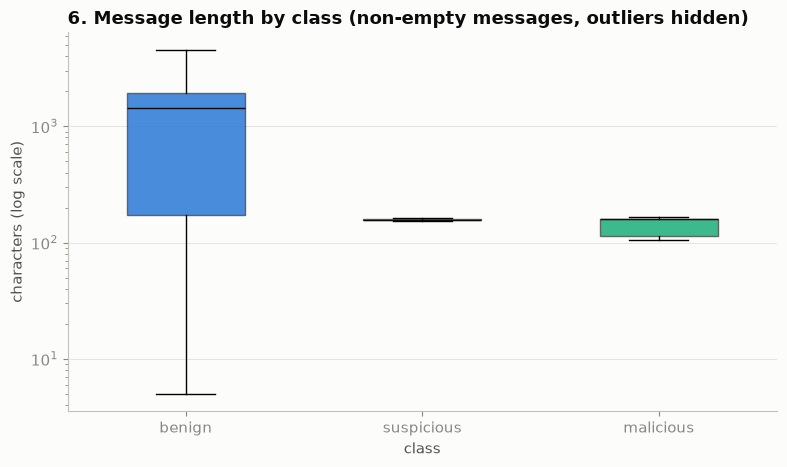

saved C:\Users\iComputers\Documents\Sem 5\PAI Project\EVIDENTIA AI\reports\figures\eda06_message_length.png


**What this means for modelling:** median length is 1438 / 157 / 158 characters (benign / suspicious / malicious), and 30.06% of benign rows have an empty message vs 0.00% / 0.00%. Length mostly reflects log format, so raw length is not used as a feature; text enters through TF-IDF with digits masked.

In [8]:
msg = train["message_sanitized"].fillna("")
train["msg_len"] = msg.str.len()
nonempty = train[train["msg_len"] > 0]
data = [nonempty.loc[nonempty.label_binary == l, "msg_len"].values for l in LABELS]
fig, ax = plt.subplots(figsize=(8, 4.8))
bp = ax.boxplot(data, tick_labels=LABELS, showfliers=False, patch_artist=True, widths=0.5)
for p, l in zip(bp["boxes"], LABELS):
    p.set_facecolor(COLOR[l]); p.set_alpha(0.85); p.set_edgecolor(INK2)
for m in bp["medians"]: m.set_color(INK)
ax.set_yscale("log"); ax.set_xlabel("class"); ax.set_ylabel("characters (log scale)")
ax.set_title("6. Message length by class (non-empty messages, outliers hidden)")
ax.grid(axis="x", visible=False)
save(fig, "eda06_message_length.png")
med = {l: int(np.median(d)) for l, d in zip(LABELS, data)}
empty = {l: float((train.loc[train.label_binary == l, "msg_len"] == 0).mean()) for l in LABELS}
FINDINGS["median_message_length"] = med; FINDINGS["empty_message_share"] = {k: round(v, 4) for k, v in empty.items()}
display(Markdown(f"**What this means for modelling:** median length is {med['benign']} / {med['suspicious']} / {med['malicious']} characters "
                 f"(benign / suspicious / malicious), and {pct(empty['benign'])} of benign rows have an empty message vs "
                 f"{pct(empty['suspicious'])} / {pct(empty['malicious'])}. Length mostly reflects log format, so raw length is not used as a feature; text enters through TF-IDF with digits masked."))

## 7. Time coverage per organisation with split cut-offs (only chart that shows test rows)

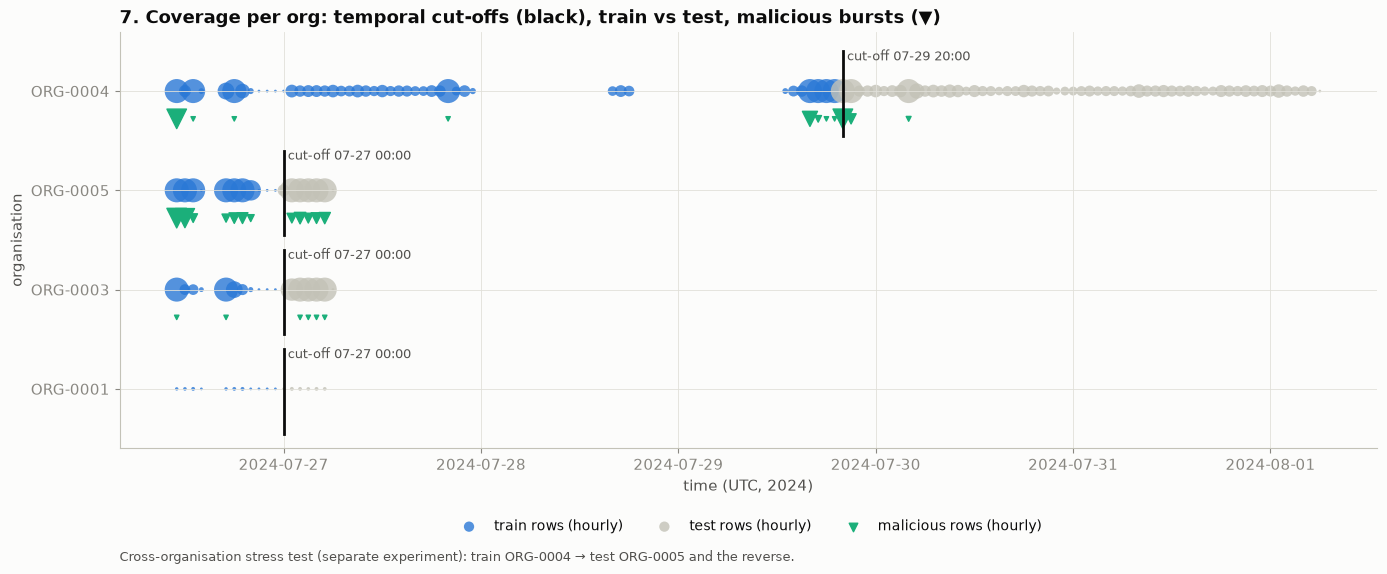

saved C:\Users\iComputers\Documents\Sem 5\PAI Project\EVIDENTIA AI\reports\figures\eda07_split_coverage.png


**What this means for modelling:** coverage is uneven (ORG-0001: 0.8 days, ORG-0003: 0.8 days, ORG-0004: 5.8 days, ORG-0005: 0.8 days) and malicious rows come in bursts, so cut-offs were placed between bursts to keep malicious rows on both sides (ORG-0004 train: 1,063 malicious; ORG-0004 test: 3,113 malicious; ORG-0005 train: 2,654 malicious; ORG-0005 test: 882 malicious). Organisations are evaluated separately and across each other, never mixed by a random split.

In [9]:
cov = coverage_all.copy()
cov["hour_bin"] = cov["ts"].dt.floor("h")
dens = cov.groupby(["org_id", "hour_bin", "is_test"]).size().reset_index(name="n")
mal = cov[cov.label_binary == "malicious"].groupby(["org_id", "hour_bin"]).size().reset_index(name="n")
orgs = ["ORG-0004", "ORG-0005", "ORG-0003", "ORG-0001"]
fig, ax = plt.subplots(figsize=(14, 6))
for i, o in enumerate(orgs):
    d = dens[dens.org_id == o]
    for is_test, col, lab in [(False, "#2a78d6", "train rows (hourly)"), (True, "#c3c2b7", "test rows (hourly)")]:
        dd = d[d.is_test == is_test]
        ax.scatter(dd.hour_bin, np.full(len(dd), i), s=np.clip(dd.n / 60, 4, 300), color=col, alpha=0.8,
                   label=lab if i == 0 else None, edgecolor="none")
    m = mal[mal.org_id == o]
    ax.scatter(m.hour_bin, np.full(len(m), i + 0.28), marker="v", s=np.clip(m.n / 3, 10, 200),
               color="#1baf7a", label="malicious rows (hourly)" if i == 0 else None)
    cut = pd.to_datetime(CUTOFFS[o], unit="s", utc=True)
    ax.plot([cut, cut], [i - 0.4, i + 0.45], color=INK, lw=2)
    ax.annotate(f"cut-off {cut:%m-%d %H:%M}", (cut, i - 0.42), fontsize=9, color=INK2, ha="left", va="top", xytext=(3, 0), textcoords="offset points")
ax.set_yticks(range(len(orgs)), orgs); ax.invert_yaxis(); ax.set_ylim(len(orgs) - 0.4, -0.6)
ax.set_xlabel("time (UTC, 2024)"); ax.set_ylabel("organisation")
ax.set_title("7. Coverage per org: temporal cut-offs (black), train vs test, malicious bursts (▼)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncols=3, fontsize=10, markerscale=0.6)
ax.annotate("Cross-organisation stress test (separate experiment): train ORG-0004 → test ORG-0005 and the reverse.",
            (0, -0.27), xycoords="axes fraction", fontsize=9, color=INK2)
save(fig, "eda07_split_coverage.png")
spl = coverage_all[coverage_all.org_id.isin(STAGE2_ORGS)].groupby(["org_id", "is_test", "label_binary"]).size().unstack(fill_value=0)
FINDINGS["split_counts"] = {f"{o}|{'test' if t else 'train'}": r.to_dict() for (o, t), r in spl.iterrows()}
txt = "; ".join(f"{o} {'test' if t else 'train'}: {r.get('malicious', 0):,} malicious" for (o, t), r in spl.iterrows())
spans = ", ".join(f"{o}: {d:.1f} days" for o, d in FINDINGS["coverage_span_days"].items())
display(Markdown(f"**What this means for modelling:** coverage is uneven ({spans}) and malicious rows come in bursts, "
                 f"so cut-offs were placed between bursts to keep malicious rows on both sides ({txt}). Organisations are evaluated "
                 f"separately and across each other, never mixed by a random split."))
del coverage_all, cov

## 8. Exact and near-duplicate messages (train)

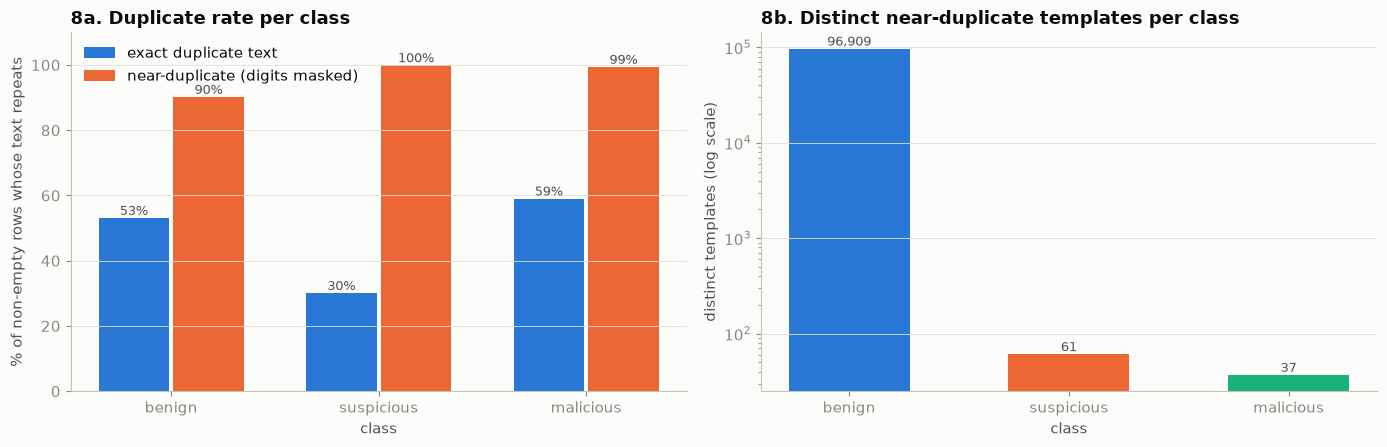

saved C:\Users\iComputers\Documents\Sem 5\PAI Project\EVIDENTIA AI\reports\figures\eda08_duplicates.png


**What this means for modelling:** 59.03% of malicious training rows repeat an exact text, malicious rows collapse to 37 templates, and 40.70% of malicious rows have text that also appears with another label. A random split would leak templates across train/test, and single-row text cannot fully separate malicious from suspicious → temporal splits, a 'novel text' test subset, and context features.

In [10]:
msg = train["message_sanitized"].fillna("")
has = msg != ""
exact_counts = msg[has].map(msg[has].value_counts())
train["dup_exact"] = False
train.loc[has, "dup_exact"] = exact_counts.values > 1
tpl = msg.str.replace(r"\d+", "0", regex=True)
tpl_counts = tpl[has].map(tpl[has].value_counts())
train["dup_template"] = False
train.loc[has, "dup_template"] = tpl_counts.values > 1
rate = train[has].groupby("label_binary")[["dup_exact", "dup_template"]].mean().reindex(LABELS)
lab_per_text = train[has].groupby("message_sanitized")["label_binary"].nunique()
conflict_texts = set(lab_per_text.index[lab_per_text > 1])
mal_conf = train[has & (train.label_binary == "malicious")]["message_sanitized"].isin(conflict_texts).mean()
n_tpl = train[has].assign(t=tpl[has]).groupby("label_binary")["t"].nunique().reindex(LABELS)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
x = np.arange(3)
b1 = axes[0].bar(x - 0.18, rate["dup_exact"]*100, 0.34, color="#2a78d6", label="exact duplicate text")
b2 = axes[0].bar(x + 0.18, rate["dup_template"]*100, 0.34, color="#eb6834", label="near-duplicate (digits masked)")
for b in list(b1) + list(b2):
    axes[0].annotate(f"{b.get_height():.0f}%", (b.get_x()+b.get_width()/2, b.get_height()), ha="center", va="bottom", fontsize=9, color=INK2)
axes[0].set_xticks(x, LABELS); axes[0].set_ylim(0, 110); axes[0].set_xlabel("class")
axes[0].set_ylabel("% of non-empty rows whose text repeats"); axes[0].set_title("8a. Duplicate rate per class"); axes[0].legend(loc="upper left")
b = axes[1].bar(LABELS, n_tpl.values, color=[COLOR[l] for l in LABELS], width=0.55)
for bb, v in zip(b, n_tpl.values):
    axes[1].annotate(f"{v:,}", (bb.get_x()+bb.get_width()/2, v), ha="center", va="bottom", fontsize=9, color=INK2)
axes[1].set_yscale("log"); axes[1].set_xlabel("class"); axes[1].set_ylabel("distinct templates (log scale)")
axes[1].set_title("8b. Distinct near-duplicate templates per class")
for ax in axes: ax.grid(axis="x", visible=False)
save(fig, "eda08_duplicates.png")
FINDINGS["duplicate_rate"] = rate.round(4).to_dict(orient="index")
FINDINGS["templates_per_class"] = n_tpl.to_dict(); FINDINGS["malicious_text_conflict_share"] = round(float(mal_conf), 4)
display(Markdown(f"**What this means for modelling:** {pct(rate.loc['malicious','dup_exact'])} of malicious training rows repeat an exact text, "
                 f"malicious rows collapse to {n_tpl['malicious']:,} templates, and {pct(mal_conf)} of malicious rows have text that also "
                 f"appears with another label. A random split would leak templates across train/test, and single-row text cannot fully "
                 f"separate malicious from suspicious → temporal splits, a 'novel text' test subset, and context features."))

## 9. Leakage evidence for every removed column (train)

`load_signals()` intentionally does not return the removed columns, so they are read here **read-only**
from the same parquet file, restricted to the same training rows (same cut-off rule). Two scores per column:

* **NMI** — normalised mutual information between the column value and `label_binary`.
* **One-feature model** — a lookup table (column value → majority label) fitted, **inside each organisation**,
  on the first 70 % of its training rows by time and scored (macro-F1) on the last 30 %. Unseen values predict `benign`.
  The cell prints the class counts of the scoring window and stops if a minority class has < 100 rows.

Kept event columns are shown in grey for reference.

eval_part label counts:
label_binary
benign        298800
suspicious     14600
malicious        347
eval_part by org:
label_binary  benign  suspicious  malicious
org_key                                    
ORG-0001         809           1          0
ORG-0003       41677          21          1
ORG-0004      177856         376         19
ORG-0005       78458       14202        327


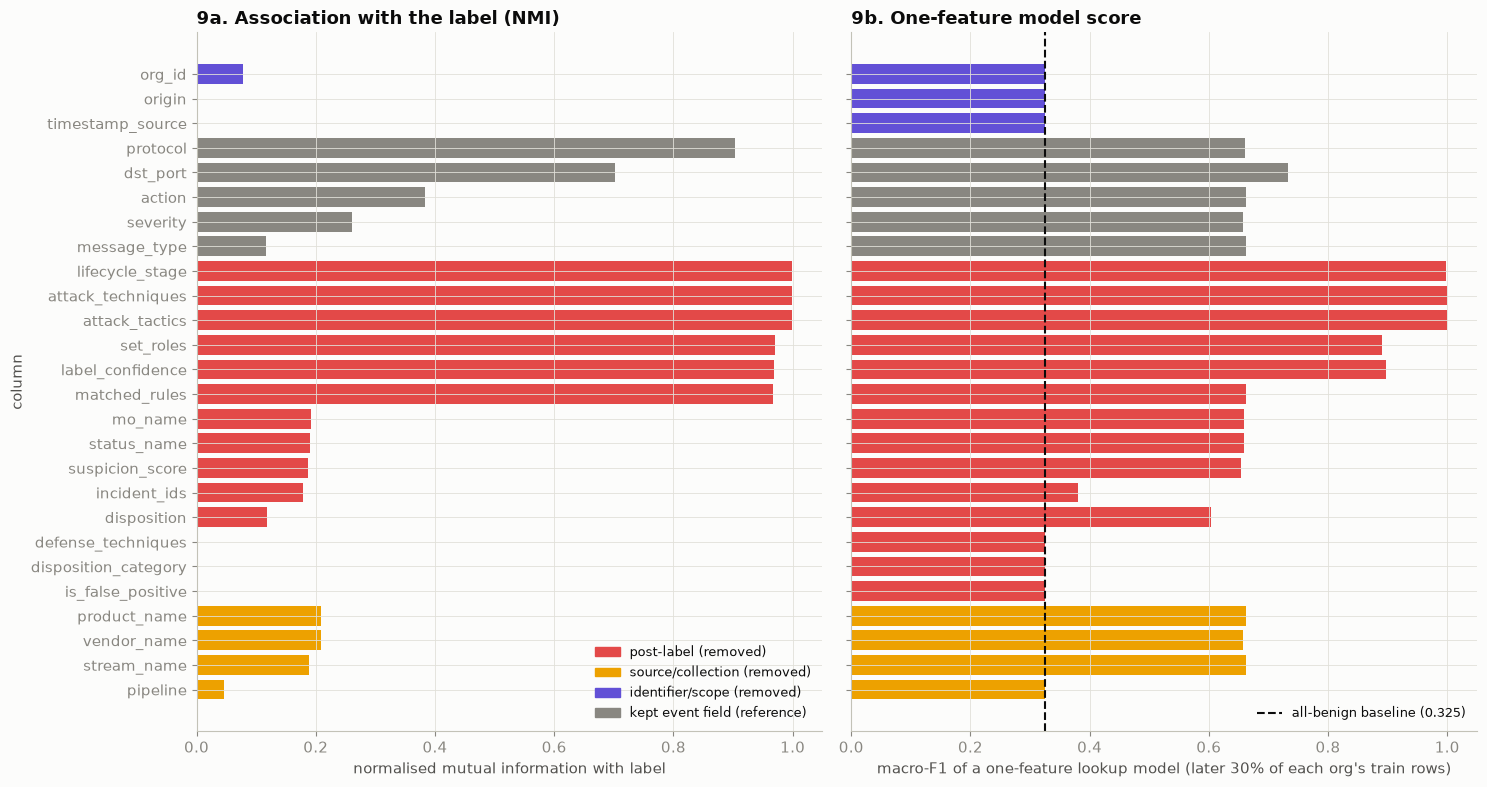

saved C:\Users\iComputers\Documents\Sem 5\PAI Project\EVIDENTIA AI\reports\figures\eda09_leakage_evidence.png


,column,group,nmi,one_feature_macro_f1,f1_suspicious,f1_malicious,populated_benign,populated_suspicious,populated_malicious
18,org_id,identifier/scope (removed),0.078,0.325,0.000,0.000,1.000,1.000,1.000
19,origin,identifier/scope (removed),0.000,0.325,0.000,0.000,1.000,1.000,1.000
20,timestamp_source,identifier/scope (removed),0.000,0.325,0.000,0.000,1.000,1.000,1.000
24,protocol,kept event field (reference),0.904,0.660,0.982,0.000,0.001,0.998,0.993
23,dst_port,kept event field (reference),0.702,0.733,0.972,0.229,0.014,0.978,0.969
22,action,kept event field (reference),0.383,0.662,0.987,0.000,0.143,0.999,0.995
25,severity,kept event field (reference),0.260,0.658,0.975,0.000,0.408,0.908,0.714
21,message_type,kept event field (reference),0.117,0.663,0.988,0.000,1.000,1.000,1.000
6,lifecycle_stage,post-label (removed),1.000,0.998,1.000,0.994,1.000,1.000,1.000
1,attack_techniques,post-label (removed),1.000,1.000,1.000,1.000,0.000,1.000,1.000


mo_name of malicious train rows: {'Data Theft': 3720}
top streams of malicious train rows per org: {'ORG-0003': {'microsoft-windows-security-auditing': 3}, 'ORG-0004': {'aws_vpc_flow_log': 1043, 'Crowdstrike Detection': 20}, 'ORG-0005': {'cisco_asa': 2651, 'barracuda_waf': 3}}


**What this means for modelling:** `lifecycle_stage`: one-feature macro-F1 0.998; `attack_techniques`: one-feature macro-F1 1.000; `attack_tactics`: one-feature macro-F1 1.000; `set_roles`: one-feature macro-F1 0.890; `label_confidence`: one-feature macro-F1 0.898; `matched_rules`: populated only for alert rows (suspicious F1 0.988); `mo_name`: populated only for malicious rows (malicious F1 1.000); `status_name`: populated only for malicious rows (malicious F1 1.000); `suspicion_score`: populated only for malicious rows (malicious F1 0.987); `incident_ids`: populated only for malicious rows (malicious F1 0.164); `disposition`: post-incident engine status (NMI 0.118, macro-F1 0.604); `defense_techniques`: no information in this capture (constant/empty); removed because it is a post-incident field; `disposition_category`: no information in this capture (constant/empty); removed because it is a post-incident field; `is_false_positive`: no information in this capture (constant/empty); removed because it is a post-incident field. All are produced by WitFoo's labelling/correlation step and are removed. Source fields are weaker than expected (best: `product_name` 0.662), but **kept** event fields are just as strong (`dst_port` 0.733) because they are populated for 1.45% of benign vs 97.78% of suspicious rows — their presence identifies the log type. So benign-vs-alert results must be read as log-type recognition even without source fields. Scoring window: 14,600 suspicious and 347 malicious rows (malicious by org: {'ORG-0005': 327, 'ORG-0004': 19, 'ORG-0003': 1}); the malicious scores therefore mostly reflect ORG-0005.

In [11]:
removed = [c for c in BANNED_POST_LABEL if c != "label_binary"] + SOURCE_FIELDS + [c for c in NEVER_FEATURES if c != "artifact_id"]
reference = ["message_type", "action", "dst_port", "protocol", "severity"]
case = " ".join(f"WHEN org_id='{o}' THEN {v}" for o, v in CUTOFFS.items())
q = (f"SELECT timestamp, label_binary, org_id AS org_key, {', '.join(f'CAST({c} AS VARCHAR) AS {c}' for c in removed + reference)} "
     f"FROM '{SIGNALS_PARQUET.as_posix()}' WHERE timestamp < CASE {case} END")
lk = duckdb.connect().execute(q).df()
assert len(lk) == n_train, (len(lk), n_train)
# Per-organisation time split: inside EACH org, the first 70% of its training rows (by time) fit the
# lookup table and the last 30% score it. A single global 70/30 cut would leave whole organisations
# (short coverage) entirely on one side.
lk = lk.sort_values(["org_key", "timestamp"]).reset_index(drop=True)
lk["_rank"] = lk.groupby("org_key")["timestamp"].rank(method="first", pct=True)
fit_part, eval_part = lk[lk["_rank"] <= 0.7], lk[lk["_rank"] > 0.7]
y_eval = eval_part["label_binary"].values
eval_counts = eval_part["label_binary"].value_counts().reindex(LABELS, fill_value=0)
print("eval_part label counts:"); print(eval_counts.to_string())
print("eval_part by org:")
print(eval_part.groupby(["org_key", "label_binary"]).size().unstack(fill_value=0).reindex(columns=LABELS, fill_value=0).to_string())
assert (eval_counts[["suspicious", "malicious"]] >= 100).all(), "evaluation window lacks minority classes; F1 would be meaningless"
FINDINGS["leakage_eval_counts"] = {k: int(v) for k, v in eval_counts.items()}
rows = []
for c in removed + reference:
    v = lk[c].fillna("∅")
    nmi = normalized_mutual_info_score(lk["label_binary"], v)
    mapping = fit_part.assign(v=fit_part[c].fillna("∅")).groupby("v")["label_binary"].agg(lambda s: s.value_counts().idxmax())
    pred = eval_part[c].fillna("∅").map(mapping).fillna("benign").values
    f1 = f1_score(y_eval, pred, labels=LABELS, average="macro", zero_division=0)
    f1_cls = f1_score(y_eval, pred, labels=LABELS, average=None, zero_division=0)
    populated = {l: float((lk.loc[lk.label_binary == l, c].fillna("").isin(["", "[]", "0.0", "0", "false"]) == False).mean()) for l in LABELS}
    group = "post-label (removed)" if c in BANNED_POST_LABEL else "source/collection (removed)" if c in SOURCE_FIELDS else \
            "identifier/scope (removed)" if c in NEVER_FEATURES else "kept event field (reference)"
    rows.append({"column": c, "group": group, "nmi": nmi, "one_feature_macro_f1": f1,
                 "f1_suspicious": f1_cls[1], "f1_malicious": f1_cls[2],
                 **{f"populated_{l}": populated[l] for l in LABELS}})
leak = pd.DataFrame(rows).sort_values(["group", "nmi"], ascending=[True, False])
base_f1 = f1_score(y_eval, np.full(len(y_eval), "benign"), labels=LABELS, average="macro", zero_division=0)
gcol = {"post-label (removed)": "#e34948", "source/collection (removed)": "#eda100",
        "identifier/scope (removed)": "#6250d6", "kept event field (reference)": MUTED}
fig, axes = plt.subplots(1, 2, figsize=(15, 8), sharey=True)
y = np.arange(len(leak))
axes[0].barh(y, leak["nmi"], color=[gcol[g] for g in leak["group"]])
axes[1].barh(y, leak["one_feature_macro_f1"], color=[gcol[g] for g in leak["group"]])
axes[1].axvline(base_f1, color=INK, ls="--", lw=1.5, label=f"all-benign baseline ({base_f1:.3f})")
axes[0].set_yticks(y, leak["column"]); axes[0].invert_yaxis()
axes[0].set_xlabel("normalised mutual information with label"); axes[0].set_ylabel("column")
axes[0].set_title("9a. Association with the label (NMI)")
axes[1].set_xlabel("macro-F1 of a one-feature lookup model (later 30% of each org's train rows)")
axes[1].set_title("9b. One-feature model score")
from matplotlib.patches import Patch
axes[0].legend(handles=[Patch(color=col, label=g) for g, col in gcol.items()], loc="lower right", fontsize=9)
axes[1].legend(loc="lower right", fontsize=9)
save(fig, "eda09_leakage_evidence.png")
pd.set_option("display.width", 200)
display(leak.round(3))
FINDINGS["malicious_mo_name_values"] = lk.loc[lk.label_binary == "malicious", "mo_name"].fillna("∅").value_counts().to_dict()
FINDINGS["malicious_streams_by_org"] = {o: g["stream_name"].value_counts().head(3).to_dict()
                                        for o, g in lk[lk.label_binary == "malicious"].groupby("org_key")}
print("mo_name of malicious train rows:", FINDINGS["malicious_mo_name_values"])
print("top streams of malicious train rows per org:", FINDINGS["malicious_streams_by_org"])
FINDINGS["leakage_table"] = leak.round(4).to_dict(orient="records"); FINDINGS["leakage_baseline_macro_f1"] = round(float(base_f1), 4)
def leak_reason(r):
    pb, ps, pm = r.populated_benign, r.populated_suspicious, r.populated_malicious
    if r.one_feature_macro_f1 >= 0.85:
        return f"one-feature macro-F1 {r.one_feature_macro_f1:.3f}"
    if pb == 0 and ps == 0 and pm == 1:
        return f"populated only for malicious rows (malicious F1 {r.f1_malicious:.3f})"
    if pb == 0 and min(ps, pm) == 1:
        return f"populated only for alert rows (suspicious F1 {r.f1_suspicious:.3f})"
    if r.nmi == 0 and r.one_feature_macro_f1 <= base_f1 + 1e-9:
        return "no information in this capture (constant/empty); removed because it is a post-incident field"
    return f"post-incident engine status (NMI {r.nmi:.3f}, macro-F1 {r.one_feature_macro_f1:.3f})"
post = leak[leak.group == "post-label (removed)"].copy()
post["reason"] = [leak_reason(r) for r in post.itertuples()]
FINDINGS["leak_reasons"] = dict(zip(post.column, post.reason))
src = leak[leak.group == "source/collection (removed)"].sort_values("one_feature_macro_f1", ascending=False)
kept = leak[leak.group == "kept event field (reference)"].sort_values("one_feature_macro_f1", ascending=False)
FINDINGS["best_source_field"] = (src.iloc[0].column, round(float(src.iloc[0].one_feature_macro_f1), 4))
FINDINGS["best_kept_field"] = (kept.iloc[0].column, round(float(kept.iloc[0].one_feature_macro_f1), 4),
                               round(float(kept.iloc[0].populated_benign), 4), round(float(kept.iloc[0].populated_suspicious), 4))
ec = FINDINGS["leakage_eval_counts"]
org_mal = eval_part[eval_part.label_binary == "malicious"]["org_key"].value_counts().to_dict()
FINDINGS["leakage_eval_malicious_by_org"] = org_mal
display(Markdown(
    "**What this means for modelling:** "
    + "; ".join(f"`{c}`: {r}" for c, r in FINDINGS["leak_reasons"].items())
    + f". All are produced by WitFoo's labelling/correlation step and are removed. "
    f"Source fields are weaker than expected (best: `{src.iloc[0].column}` {src.iloc[0].one_feature_macro_f1:.3f}), but **kept** event fields "
    f"are just as strong (`{kept.iloc[0].column}` {kept.iloc[0].one_feature_macro_f1:.3f}) because they are populated for "
    f"{pct(kept.iloc[0].populated_benign)} of benign vs {pct(kept.iloc[0].populated_suspicious)} of suspicious rows — their presence identifies the log type. "
    f"So benign-vs-alert results must be read as log-type recognition even without source fields. "
    f"Scoring window: {ec['suspicious']:,} suspicious and {ec['malicious']:,} malicious rows "
    f"(malicious by org: {org_mal}); the malicious scores therefore mostly reflect "
    f"{max(org_mal, key=org_mal.get)}."))

## 10. Write `reports/eda_summary.md`

In [12]:
F = FINDINGS
cc, cs = F["class_counts"], F["class_share"]
lt = pd.DataFrame(F["leakage_table"])
post = lt[lt.group == "post-label (removed)"].sort_values("one_feature_macro_f1", ascending=False)
src = lt[lt.group == "source/collection (removed)"].sort_values("one_feature_macro_f1", ascending=False)
split_lines = "\n".join(f"| {k.split('|')[0]} | {k.split('|')[1]} | {v.get('benign', 0):,} | {v.get('suspicious', 0):,} | {v.get('malicious', 0):,} |"
                        for k, v in F["split_counts"].items())
summary = f"""# EDA summary (training portion)

Generated by `notebooks/01_eda.ipynb` on {time.strftime('%Y-%m-%d %H:%M')}. All numbers below are computed on the
**training portion** ({F['rows_train']:,} of {F['rows_all']:,} rows; `timestamp < CUTOFFS[org_id]`) unless marked otherwise.
Figures: `reports/figures/eda01_*.png` … `eda09_*.png`.

## Key findings

1. **Severe imbalance.** benign {cc['benign']:,} ({pct(cs['benign'])}), suspicious {cc['suspicious']:,} ({pct(cs['suspicious'])}),
   malicious {cc['malicious']:,} ({pct(cs['malicious'])}).
2. **Only two organisations carry the minority classes:** {', '.join(F['orgs_with_500plus_malicious'])} have ≥500 malicious training rows.
3. **Alerts come from two log types.** {pct(F['top2_types_share_of_alerts'])} of suspicious+malicious training rows are `{F['top2_alert_types'][0]}` or `{F['top2_alert_types'][1]}`
   (out of {F['n_message_types_train']} message types).
4. **Malicious events are bursty.** {pct(F['malicious_peak_hour_share'])} of malicious training rows fall in one hour of the day ({F['malicious_peak_hour_utc']:02d}:00 UTC).
5. **Heavy duplication.** {pct(F['duplicate_rate']['malicious']['dup_exact'])} of malicious rows repeat an exact text; malicious rows form only
   {F['templates_per_class']['malicious']:,} digit-masked templates; {pct(F['malicious_text_conflict_share'])} of malicious rows share their exact text with rows of another label.
6. **Missingness is class-dependent** (largest gaps: {', '.join(f'`{k}` {pct(v)}' for k, v in F['largest_missingness_gap_between_classes'].items())}).
7. **Post-label columns leak the label** (all-benign baseline macro-F1 {F['leakage_baseline_macro_f1']:.3f}):
   {'; '.join(f'`{c}` — {r}' for c, r in F['leak_reasons'].items())}.
8. **Kept event fields also encode the log type.** Best source field `{F['best_source_field'][0]}` scores {F['best_source_field'][1]:.3f} alone,
   but kept field `{F['best_kept_field'][0]}` scores {F['best_kept_field'][1]:.3f} because it is populated in {pct(F['best_kept_field'][2])} of benign vs
   {pct(F['best_kept_field'][3])} of suspicious rows.

Split sizes (only place the test portion is used):

| Org | Portion | Benign | Suspicious | Malicious |
|---|---|---|---|---|
{split_lines}

## Five modelling decisions justified by the EDA

1. **Class weighting + imbalance-aware metrics.** Because malicious is {pct(cs['malicious'])} of rows, models use
   `class_weight="balanced"` and are judged by macro-F1, per-class recall and PR-AUC — not accuracy (all-benign would score {pct(cs['benign'])}).
2. **Drop post-label columns** ({', '.join(f'`{c}`' for c in F['leak_reasons'])}): each is produced by the labelling/correlation step;
   the per-column evidence is in finding 7 and chart 9.
3. **Exclude source/collection fields from main models** (`{'`, `'.join(src.column)}`) and identifiers (`org_id`, `origin`,
   `timestamp_source`, `artifact_id`); source fields are only added back in an ablation. Because kept fields also reveal the log type
   (finding 8), benign-vs-alert scores are reported as log-type recognition, not threat detection.
4. **Temporal, incident-aware splits per organisation, plus cross-organisation tests** — never random. Bursty malicious
   activity (finding 4) and template duplication (finding 5) would make a random split leak near-identical rows into test.
5. **Hierarchical task + context features.** Benign-vs-alert is mostly log-type recognition (finding 3), and text cannot fully separate
   suspicious from malicious (finding 5), so stage 2 (suspicious vs malicious) adds past-only behavioural context features and is
   evaluated on a "novel text" subset as well.

## Known limitations

- Labels come from WitFoo Precinct's automated correlation, not analyst-verified ground truth (dataset card).
- Coverage is uneven (span per org, all rows): {', '.join(f'{o} {d:.1f} days' for o, d in F['coverage_span_days'].items())}.
- Only {', '.join(F['orgs_with_500plus_malicious'])} have ≥500 malicious training rows; their malicious rows come from these log streams
  ({'; '.join(o + ': ' + ', '.join(st) for o, st in F['malicious_streams_by_org'].items())}), so cross-organisation transfer is structurally hard.
- `mo_name` of malicious training rows: {F['malicious_mo_name_values']} — {'a single modus operandi, so attack-type classification is not possible' if len(F['malicious_mo_name_values']) == 1 else 'more than one value exists'}.
- `timestamp` is ingest time (dataset card); device `event_time` is not loaded here — see `reports/DATASET_AUDIT.md` §8 (full data) for its coverage.
- The leakage scoring window holds {F['leakage_eval_counts']['malicious']:,} malicious rows, by org {F['leakage_eval_malicious_by_org']}; malicious scores mostly reflect one organisation.
- {F['train_rows_dropped_crossing_incidents']} malicious training-side rows belong to incidents that cross a cut-off ({F['crossing_rows_by_org']}); the training pipeline drops them, these EDA statistics still include them.
"""
(ROOT / "reports" / "eda_summary.md").write_text(summary, encoding="utf-8")
print(f"wrote {ROOT / 'reports' / 'eda_summary.md'}  |  notebook runtime {time.time() - T0:.0f}s")

wrote C:\Users\iComputers\Documents\Sem 5\PAI Project\EVIDENTIA AI\reports\eda_summary.md  |  notebook runtime 459s
